## Summative Lab: Forest Fires Prevention

### Step 1: Load the Dataset

*   Install and import the ucimlrepo library.
*   Load the Forest Fires dataset:
 *   Predictors: Features from forest_fires.data.features.
 *   Target: forest_fires.data.targets.

In [17]:
# Run pip install if necessary to access the UCI ML Repository (uncomment the next line)
# ! pip install ucimlrepo

In [18]:
# Data
from ucimlrepo import fetch_ucirepo

forest_fires = fetch_ucirepo(id=162)
X = forest_fires.data.features
y = forest_fires.data.targets

# Display dataset structure
print(X.info())
print(X.describe())
print(y.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
dtypes: float64(7), int64(3), object(2)
memory usage: 48.6+ KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   
std      2.313778    1.229900    5.520111   64.046482  248.066192 

### Step 2: EDA

* Examine the dataset structure and summary statistics.
* Analyze correlations between predictors and the target variable.
* Plot scatterplots for key predictors vs. the target.
* Generate a residual plot to check for randomness in residuals.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# ── Combine features and target for exploration ──
df = X.copy()
df['area'] = y.values

print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nSummary statistics:")
df.describe()

Shape: (517, 13)

Missing values:
 X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

Summary statistics:


,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


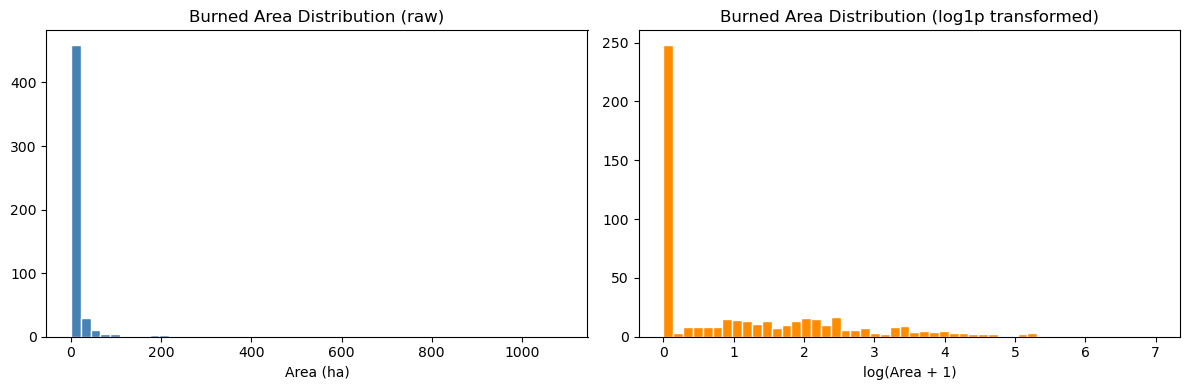

Skewness (raw):       12.85
Skewness (log1p):     1.22
Observations with area = 0: 247 / 517


In [20]:
# ── Target distribution (area is heavily right-skewed) ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['area'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Burned Area Distribution (raw)')
axes[0].set_xlabel('Area (ha)')

axes[1].hist(np.log1p(df['area']), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Burned Area Distribution (log1p transformed)')
axes[1].set_xlabel('log(Area + 1)')

plt.tight_layout()
plt.show()

print(f"Skewness (raw):       {df['area'].skew():.2f}")
print(f"Skewness (log1p):     {np.log1p(df['area']).skew():.2f}")
print(f"Observations with area = 0: {(df['area'] == 0).sum()} / {len(df)}")

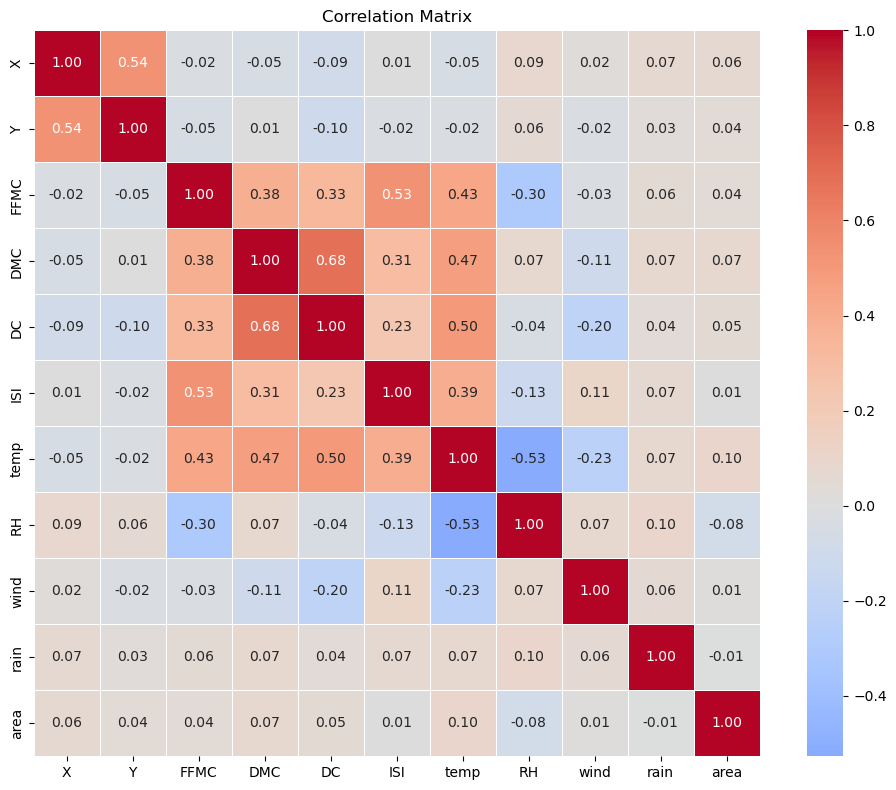

In [21]:
# ── Correlation heatmap (numeric features only) ──
numeric_cols = df.select_dtypes(include='number').columns.tolist()
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, square=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

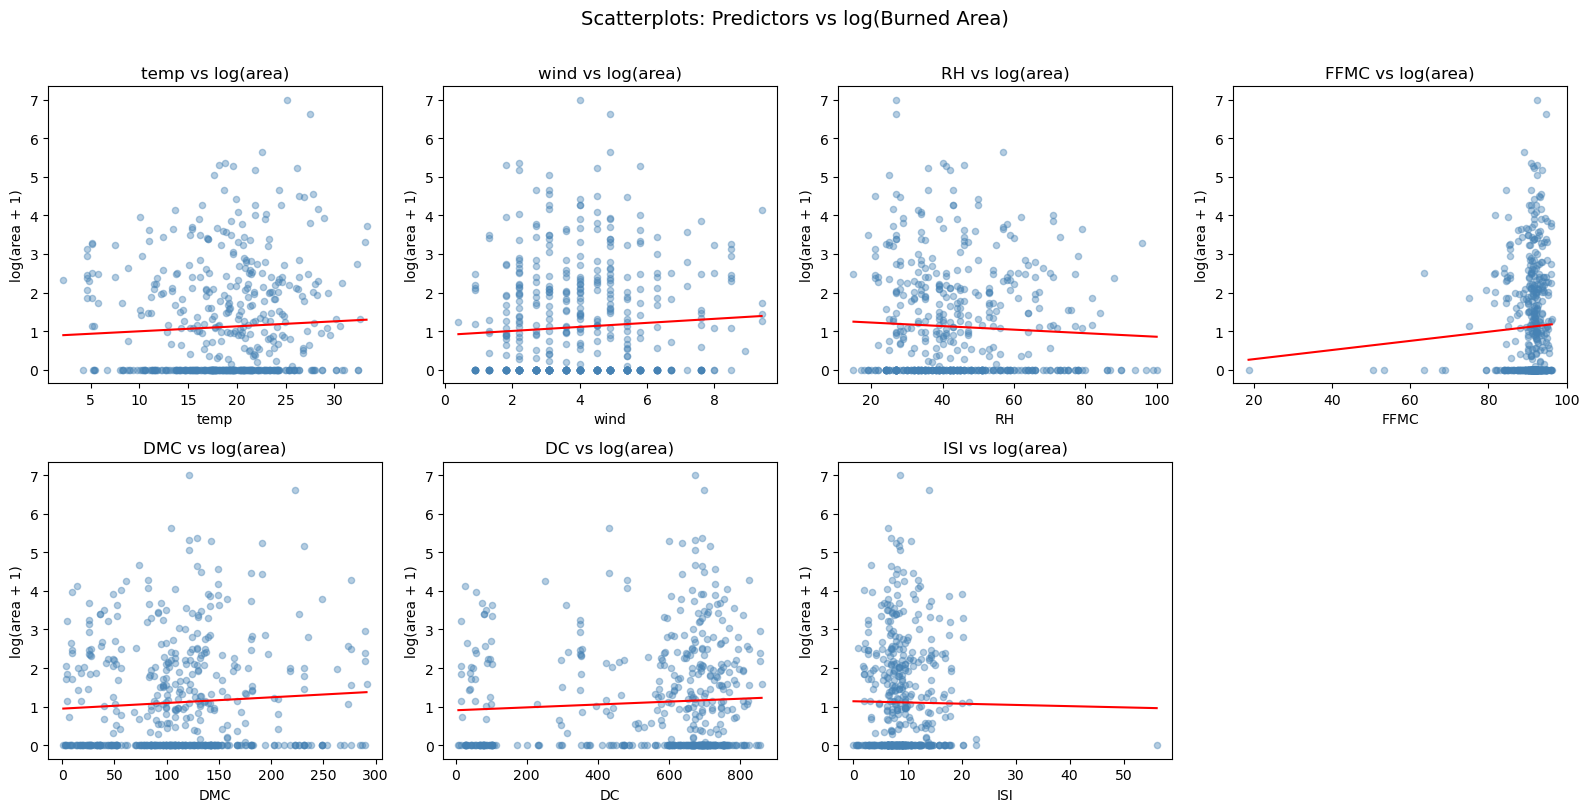

In [22]:
# ── Scatterplots: key continuous predictors vs log(area) ──
log_area = np.log1p(df['area'])
predictors = ['temp', 'wind', 'RH', 'FFMC', 'DMC', 'DC', 'ISI']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(predictors):
    axes[i].scatter(df[col], log_area, alpha=0.4, s=20, color='steelblue')
    # add a simple OLS trend line
    m, b = np.polyfit(df[col], log_area, 1)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    axes[i].plot(x_line, m * x_line + b, color='red', linewidth=1.5)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('log(area + 1)')
    axes[i].set_title(f'{col} vs log(area)')

axes[-1].set_visible(False)
plt.suptitle('Scatterplots: Predictors vs log(Burned Area)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

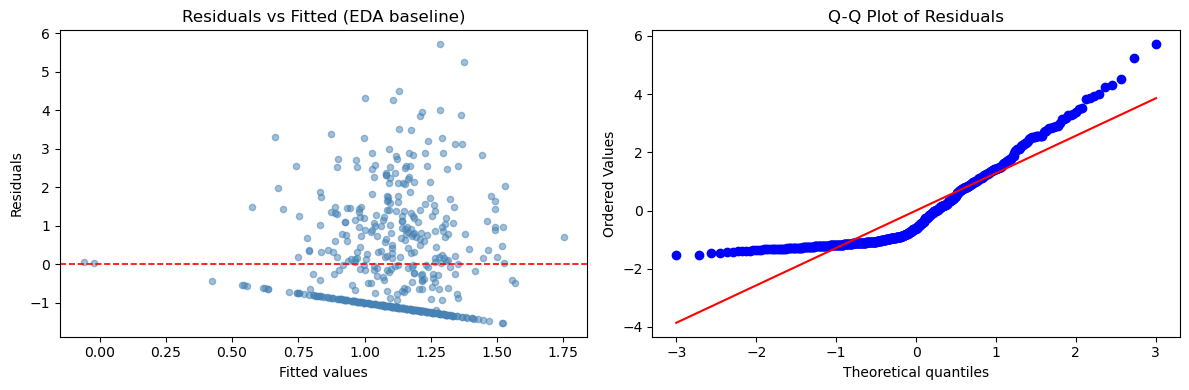

In [23]:
# ── Residual plot from a simple OLS baseline ──
from sklearn.linear_model import LinearRegression

numeric_feats = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
log_area = np.log1p(df['area'])

scaler_eda = StandardScaler()
X_eda = scaler_eda.fit_transform(df[numeric_feats])

lr_eda = LinearRegression()
lr_eda.fit(X_eda, log_area)
residuals_eda = log_area - lr_eda.predict(X_eda)
fitted_eda    = lr_eda.predict(X_eda)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted_eda, residuals_eda, alpha=0.5, color='steelblue', s=20)
axes[0].axhline(0, color='red', linewidth=1.2, linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (EDA baseline)')

import scipy.stats as stats
stats.probplot(residuals_eda, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

### Step 3: Fit the regression models

* Fit a baseline multiple linear regression model with key predictors.
* Include nonlinear terms (e.g., quadratic transformations for significant predictors).
* Add interaction terms (e.g., between predictors with strong correlations).
* Incorporate indicator variables if categorical variables are present.
* Apply transformations (e.g., logarithmic transformations for skewed predictors).

In [24]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Log-transform target (standard approach for this dataset)
df['log_area'] = np.log1p(df['area'])

# ── Encode categoricals ──
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
day_order   = ['mon','tue','wed','thu','fri','sat','sun']

df['month'] = pd.Categorical(df['month'], categories=month_order)
df['day']   = pd.Categorical(df['day'],   categories=day_order)

month_dummies = pd.get_dummies(df['month'], prefix='month', drop_first=True, dtype=float)
day_dummies   = pd.get_dummies(df['day'],   prefix='day',   drop_first=True, dtype=float)

# Numeric features
num_feats = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

# ── MODEL 1: Baseline (numeric only) ──
X1 = sm.add_constant(df[num_feats])
model1 = sm.OLS(df['log_area'], X1).fit()
print("MODEL 1 — Baseline (numeric features)")
print(model1.summary())

MODEL 1 — Baseline (numeric features)
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.288
Date:                Sat, 06 Jun 2026   Prob (F-statistic):              0.247
Time:                        15:17:05   Log-Likelihood:                -901.28
No. Observations:                 517   AIC:                             1821.
Df Residuals:                     508   BIC:                             1859.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         

In [25]:
# ── MODEL 2: With categorical indicator variables ──
X2 = pd.concat([df[num_feats], month_dummies, day_dummies], axis=1)
X2 = sm.add_constant(X2)
model2 = sm.OLS(df['log_area'], X2).fit()
print("MODEL 2 — With categorical (month & day) indicators")
print(model2.summary())

MODEL 2 — With categorical (month & day) indicators
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.068
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     1.442
Date:                Sat, 06 Jun 2026   Prob (F-statistic):             0.0778
Time:                        15:17:05   Log-Likelihood:                -888.15
No. Observations:                 517   AIC:                             1828.
Df Residuals:                     491   BIC:                             1939.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


In [26]:
# ── MODEL 3: Quadratic terms for temp and DMC ──
df['temp_sq'] = df['temp'] ** 2
df['DMC_sq']  = df['DMC']  ** 2

X3_cols = num_feats + ['temp_sq', 'DMC_sq']
X3 = sm.add_constant(df[X3_cols])
model3 = sm.OLS(df['log_area'], X3).fit()
print("MODEL 3 — Baseline + quadratic terms (temp², DMC²)")
print(model3.summary())

MODEL 3 — Baseline + quadratic terms (temp², DMC²)
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     2.135
Date:                Sat, 06 Jun 2026   Prob (F-statistic):             0.0205
Time:                        15:17:05   Log-Likelihood:                -895.78
No. Observations:                 517   AIC:                             1814.
Df Residuals:                     506   BIC:                             1860.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c

In [27]:
# ── MODEL 4: Interaction term (temp × wind) ──
df['temp_x_wind'] = df['temp'] * df['wind']
df['temp_x_RH']   = df['temp'] * df['RH']

X4_cols = num_feats + ['temp_sq', 'DMC_sq', 'temp_x_wind', 'temp_x_RH']
X4 = sm.add_constant(df[X4_cols])
model4 = sm.OLS(df['log_area'], X4).fit()
print("MODEL 4 — + interaction terms (temp×wind, temp×RH)")
print(model4.summary())

MODEL 4 — + interaction terms (temp×wind, temp×RH)
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     2.032
Date:                Sat, 06 Jun 2026   Prob (F-statistic):             0.0201
Time:                        15:17:05   Log-Likelihood:                -894.26
No. Observations:                 517   AIC:                             1815.
Df Residuals:                     504   BIC:                             1870.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

### Step 4: Evaluate model diagnostics

* Compare models using metrics like R², adjusted R², AIC, and BIC.
* Plot residuals and create Q-Q plots to assess normality.
* Identify influential observations using Cook's Distance.

In [28]:
# ── Model comparison table ──
models = {
    'Model 1 (Baseline)':           model1,
    'Model 2 (+Categoricals)':      model2,
    'Model 3 (+Quadratics)':        model3,
    'Model 4 (+Interactions)':      model4,
}

comparison = pd.DataFrame({
    name: {
        'R²':          round(m.rsquared,      4),
        'Adj. R²':     round(m.rsquared_adj,  4),
        'AIC':         round(m.aic,            2),
        'BIC':         round(m.bic,            2),
        'F-stat':      round(m.fvalue,         2),
        'F p-value':   round(m.f_pvalue,       4),
        'Num. Params': int(m.df_model) + 1,
    }
    for name, m in models.items()
}).T

print(comparison.to_string())

                             R²  Adj. R²      AIC      BIC  F-stat  F p-value  Num. Params
Model 1 (Baseline)       0.0199   0.0044  1820.56  1858.79    1.29     0.2472          9.0
Model 2 (+Categoricals)  0.0684   0.0210  1828.30  1938.75    1.44     0.0778         26.0
Model 3 (+Quadratics)    0.0405   0.0215  1813.57  1860.30    2.14     0.0205         11.0
Model 4 (+Interactions)  0.0461   0.0234  1814.51  1869.74    2.03     0.0201         13.0


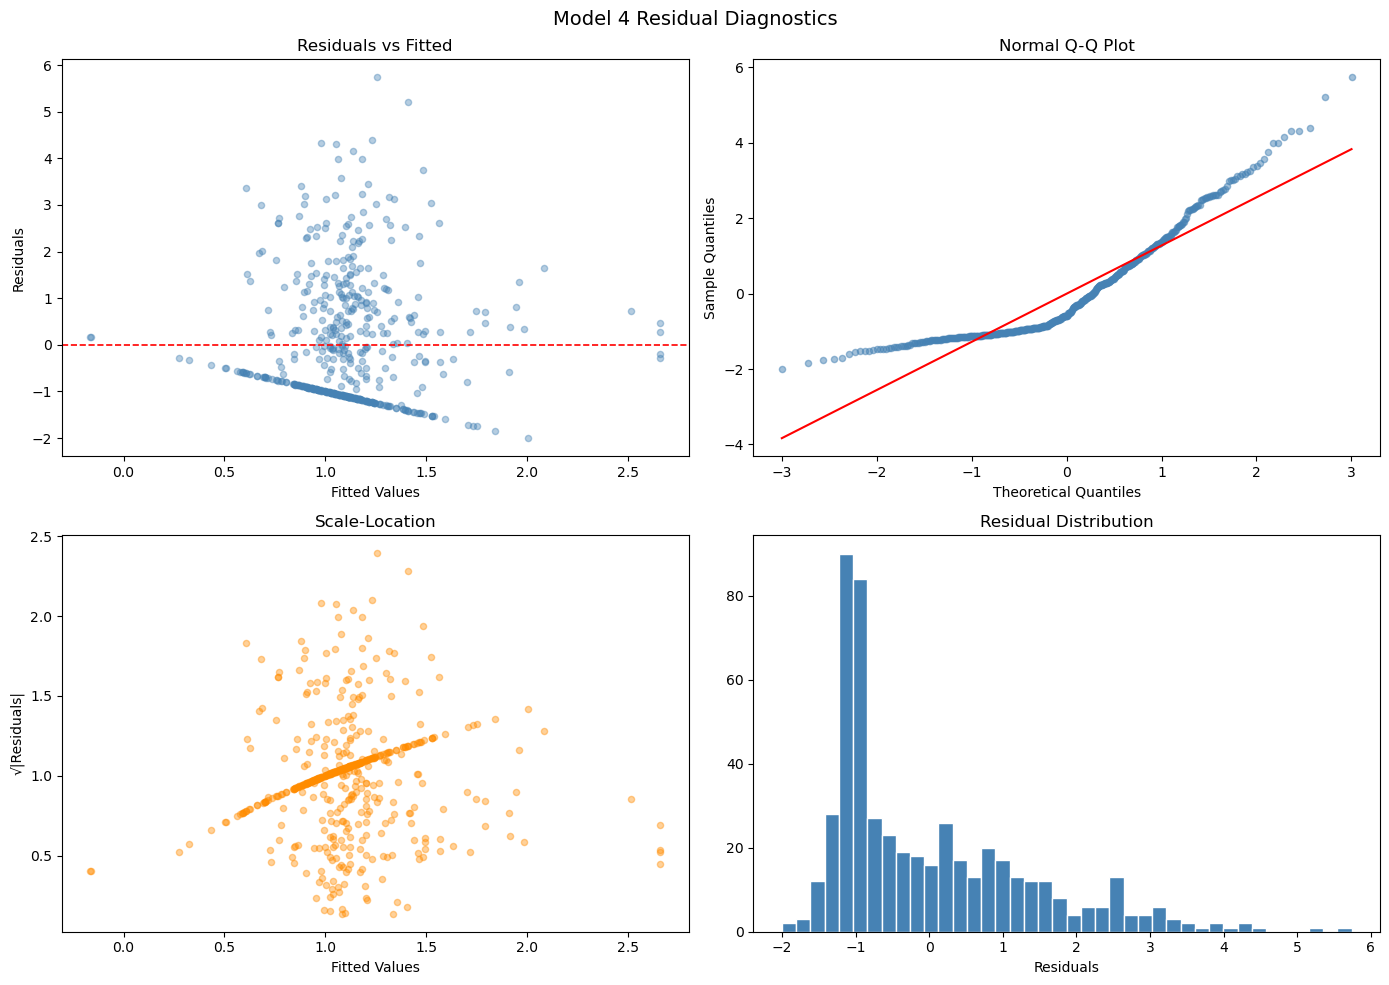


Omnibus test:   98.7886  p = 0.0000
Jarque-Bera:    155.1733  p = 0.0000
Skew:           1.2305
Kurtosis:       4.0707
Durbin-Watson:  0.9414


In [29]:
# ── Residual diagnostics for best model (Model 4) ──
best_model = model4

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Residuals vs Fitted
fitted    = best_model.fittedvalues
residuals = best_model.resid

axes[0,0].scatter(fitted, residuals, alpha=0.4, s=20, color='steelblue')
axes[0,0].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[0,0].set_xlabel('Fitted Values')
axes[0,0].set_ylabel('Residuals')
axes[0,0].set_title('Residuals vs Fitted')

# 2) Q-Q plot
import scipy.stats as stats
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[0,1].scatter(osm, osr, alpha=0.5, s=20, color='steelblue')
axes[0,1].plot(osm, slope * np.array(osm) + intercept, color='red', linewidth=1.5)
axes[0,1].set_xlabel('Theoretical Quantiles')
axes[0,1].set_ylabel('Sample Quantiles')
axes[0,1].set_title('Normal Q-Q Plot')

# 3) Scale-Location
sqrt_abs_res = np.sqrt(np.abs(residuals))
axes[1,0].scatter(fitted, sqrt_abs_res, alpha=0.4, s=20, color='darkorange')
axes[1,0].set_xlabel('Fitted Values')
axes[1,0].set_ylabel('√|Residuals|')
axes[1,0].set_title('Scale-Location')

# 4) Residual histogram
axes[1,1].hist(residuals, bins=40, color='steelblue', edgecolor='white')
axes[1,1].set_xlabel('Residuals')
axes[1,1].set_title('Residual Distribution')

plt.suptitle("Model 4 Residual Diagnostics", fontsize=14)
plt.tight_layout()
plt.show()

# OLS normality test stats (use stattools directly — diagn is RLM-only)
from statsmodels.stats.stattools import omni_normtest, jarque_bera, durbin_watson
from scipy.stats import skew, kurtosis

omni_stat, omni_p = omni_normtest(residuals)
jb_stat, jb_p, jb_skew, jb_kurt = jarque_bera(residuals)
dw = durbin_watson(residuals)

print(f"\nOmnibus test:   {omni_stat:.4f}  p = {omni_p:.4f}")
print(f"Jarque-Bera:    {jb_stat:.4f}  p = {jb_p:.4f}")
print(f"Skew:           {skew(residuals):.4f}")
print(f"Kurtosis:       {kurtosis(residuals, fisher=False):.4f}")
print(f"Durbin-Watson:  {dw:.4f}")

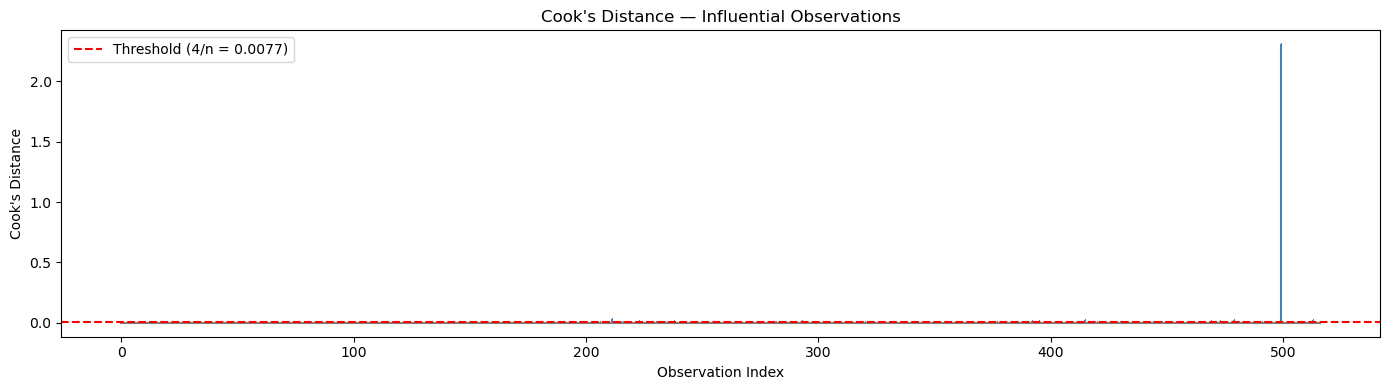

Influential observations (Cook's D > 4/n): 20


In [30]:
# ── Cook's Distance ──
from statsmodels.stats.outliers_influence import OLSInfluence

influence = OLSInfluence(best_model)
cooks_d, _ = influence.cooks_distance

fig, ax = plt.subplots(figsize=(14, 4))
ax.stem(range(len(cooks_d)), cooks_d, markerfmt=',', linefmt='steelblue',
        basefmt='grey')
threshold = 4 / len(df)
ax.axhline(threshold, color='red', linestyle='--', label=f"Threshold (4/n = {threshold:.4f})")
ax.set_xlabel('Observation Index')
ax.set_ylabel("Cook's Distance")
ax.set_title("Cook's Distance — Influential Observations")
ax.legend()
plt.tight_layout()
plt.show()

n_influential = (cooks_d > threshold).sum()
print(f"Influential observations (Cook's D > 4/n): {n_influential}")

### Step 5: Apply regularization

* Use Ridge (L2) and Lasso (L1) regression from sklearn to handle multicollinearity.
* Extract coefficients and calculate Mean Squared Error (MSE).
* Compare the performance of Ridge and Lasso models.

In [31]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler

# ── Build feature matrix for regularized models ──
X_reg_df = pd.concat([df[num_feats], month_dummies, day_dummies,
                       df[['temp_sq', 'DMC_sq', 'temp_x_wind', 'temp_x_RH']]], axis=1)
y_reg = df['log_area'].values

scaler = StandardScaler()
X_reg  = scaler.fit_transform(X_reg_df)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ── Hyperparameter search: alpha grid ──
alphas = [0.001, 0.01, 0.1, 1, 5, 10, 50, 100]

results = {}
for alpha in alphas:
    for name, model in [('Ridge', Ridge(alpha=alpha)),
                        ('Lasso', Lasso(alpha=alpha, max_iter=10000)),
                        ('ElasticNet', ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000))]:
        cv_mse = -cross_val_score(model, X_reg, y_reg,
                                  scoring='neg_mean_squared_error', cv=kf).mean()
        results[(name, alpha)] = cv_mse

# ── Best alpha per model type ──
for model_name in ['Ridge', 'Lasso', 'ElasticNet']:
    sub = {k: v for k, v in results.items() if k[0] == model_name}
    best_key = min(sub, key=sub.get)
    print(f"{model_name}: best alpha = {best_key[1]}, CV MSE = {sub[best_key]:.4f}")

Ridge: best alpha = 100, CV MSE = 1.9846
Lasso: best alpha = 0.1, CV MSE = 1.9260
ElasticNet: best alpha = 0.1, CV MSE = 1.9270


In [32]:
# ── Fit final regularized models with best alphas ──
# (adjust these values if you saw a different optimum above)
best_ridge = Ridge(alpha=10)
best_lasso = Lasso(alpha=0.01, max_iter=10000)
best_enet  = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)

for name, model in [('Ridge', best_ridge), ('Lasso', best_lasso), ('ElasticNet', best_enet)]:
    model.fit(X_reg, y_reg)
    preds  = model.predict(X_reg)
    mse    = mean_squared_error(y_reg, preds)
    r2     = r2_score(y_reg, preds)
    n_zero = np.sum(np.abs(model.coef_) < 1e-6)
    print(f"{name:12s} | Train R² = {r2:.4f} | Train MSE = {mse:.4f} | Zeroed coefs = {n_zero}")

Ridge        | Train R² = 0.0736 | Train MSE = 1.8081 | Zeroed coefs = 0
Lasso        | Train R² = 0.0662 | Train MSE = 1.8225 | Zeroed coefs = 8
ElasticNet   | Train R² = 0.0700 | Train MSE = 1.8152 | Zeroed coefs = 5


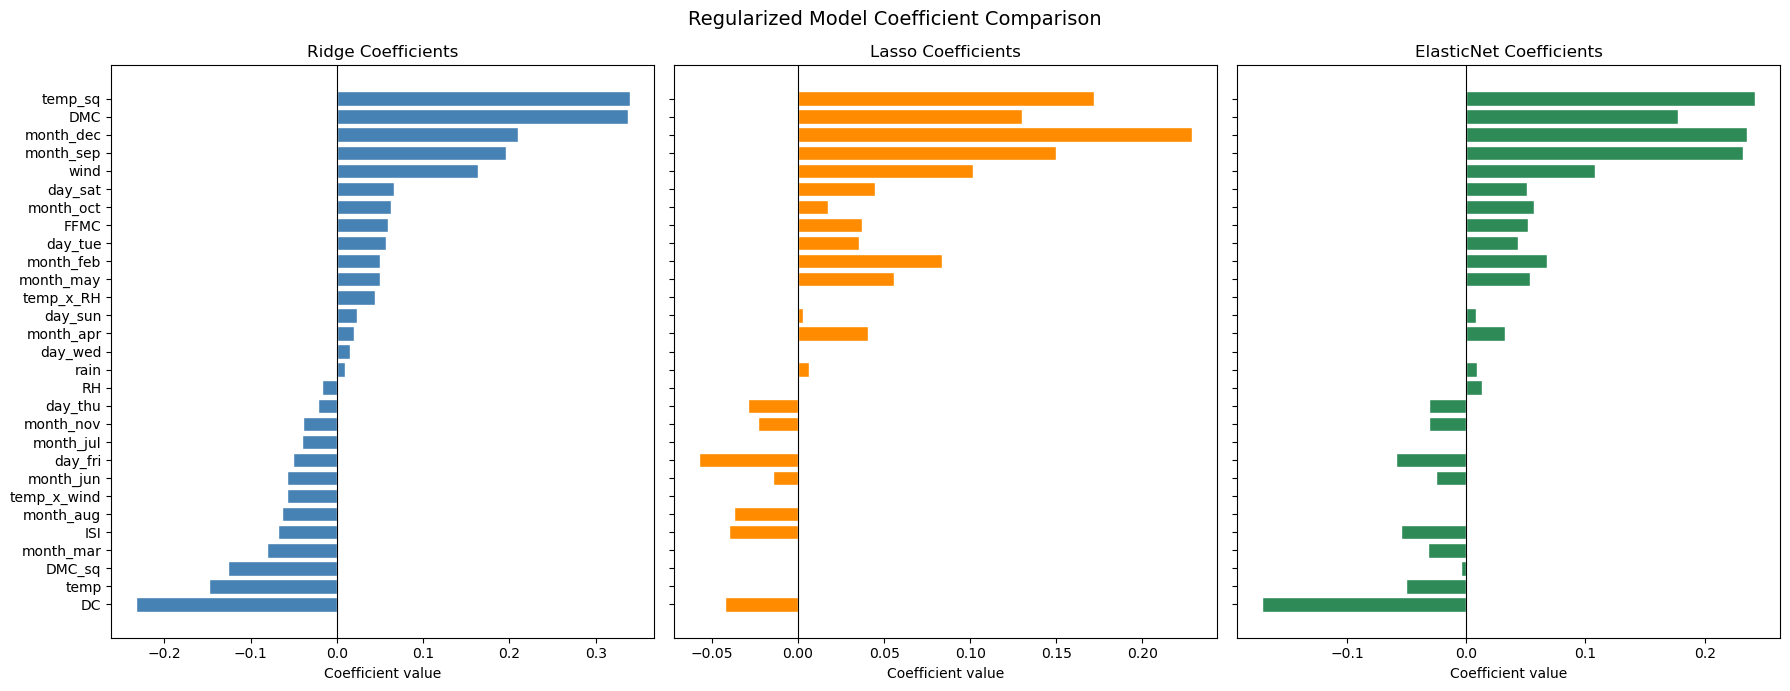

In [33]:
# ── Coefficient comparison plot ──
feature_names = list(X_reg_df.columns)

coef_df = pd.DataFrame({
    'Feature':    feature_names,
    'Ridge':      best_ridge.coef_,
    'Lasso':      best_lasso.coef_,
    'ElasticNet': best_enet.coef_,
})
coef_df = coef_df.set_index('Feature')

fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
colors = {'Ridge': 'steelblue', 'Lasso': 'darkorange', 'ElasticNet': 'seagreen'}

for ax, col in zip(axes, ['Ridge', 'Lasso', 'ElasticNet']):
    vals = coef_df[col].sort_values()
    bars = ax.barh(vals.index, vals.values, color=colors[col], edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{col} Coefficients')
    ax.set_xlabel('Coefficient value')

plt.suptitle('Regularized Model Coefficient Comparison', fontsize=14)
plt.tight_layout()
plt.show()

### Step 6: Prepare the data for binary classification

* Create a binary target variable based on a threshold in y (e.g., median or other percentile).
* Select relevant predictors and scale them using StandardScaler.

In [34]:
from sklearn.model_selection import train_test_split

# ── Binary target: 1 if area > median (excluding zeros), 0 otherwise ──
# Median of non-zero areas gives a meaningful "large fire" threshold
nonzero_median = df.loc[df['area'] > 0, 'area'].median()
print(f"Non-zero median burned area: {nonzero_median:.2f} ha")

threshold = nonzero_median
df['large_fire'] = (df['area'] > threshold).astype(int)
print(f"\nClass distribution:")
print(df['large_fire'].value_counts(normalize=True).round(3))

# ── Feature selection for classification ──
clf_feats = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

X_clf = df[clf_feats].copy()
y_clf = df['large_fire'].values

scaler_clf = StandardScaler()
X_clf_scaled = scaler_clf.fit_transform(X_clf)
X_clf_scaled = pd.DataFrame(X_clf_scaled, columns=clf_feats)

# ── Train / test split ──
X_train, X_test, y_train, y_test = train_test_split(
    X_clf_scaled, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print(f"\nTraining set: {X_train.shape[0]} observations")
print(f"Test set:     {X_test.shape[0]} observations")

Non-zero median burned area: 6.37 ha

Class distribution:
large_fire
0    0.739
1    0.261
Name: proportion, dtype: float64

Training set: 413 observations
Test set:     104 observations


### Step 7: Train and evaluate a logistic regression model

Train a logistic regression model using the scaled predictors.

* Display coefficients and the intercept.
* Predict probabilities and binary outcomes.
* Evaluate performance using accuracy, confusion matrix, precision, recall, and F1-score.

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                              classification_report, roc_auc_score,
                              RocCurveDisplay)

# ── Train logistic regression ──
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# ── Coefficients ──
coef_series = pd.Series(log_reg.coef_[0], index=clf_feats)
print("Intercept:", round(log_reg.intercept_[0], 4))
print("\nCoefficients (log-odds):")
print(coef_series.sort_values(ascending=False).round(4))

Intercept: -1.0491

Coefficients (log-odds):
rain    0.1343
DMC     0.0974
DC      0.0657
wind    0.0525
FFMC    0.0206
ISI    -0.0194
temp   -0.1912
RH     -0.3125
dtype: float64


In [36]:
# ── Predictions & evaluation ──
y_pred      = log_reg.predict(X_test)
y_prob      = log_reg.predict_proba(X_test)[:, 1]

acc  = accuracy_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {acc:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Small fire', 'Large fire']))

Accuracy:  0.7404
ROC-AUC:   0.4808

Classification Report:
              precision    recall  f1-score   support

  Small fire       0.74      1.00      0.85        77
  Large fire       0.00      0.00      0.00        27

    accuracy                           0.74       104
   macro avg       0.37      0.50      0.43       104
weighted avg       0.55      0.74      0.63       104



c:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


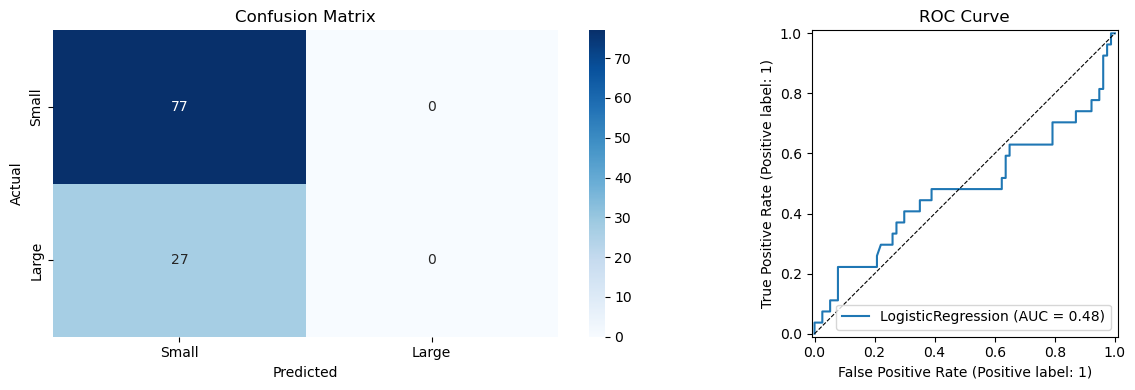

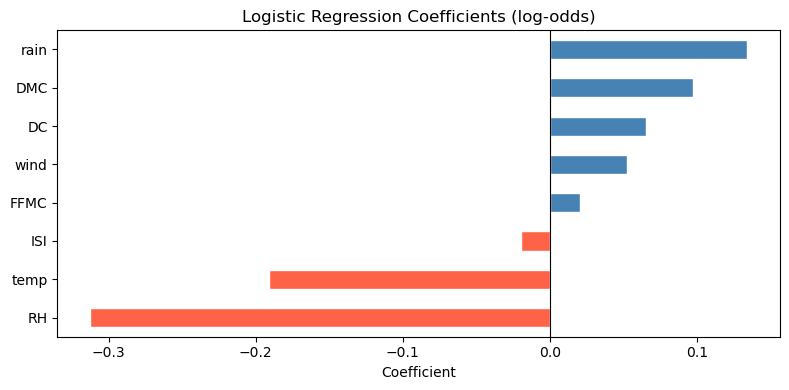

In [37]:
# ── Confusion matrix ──
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Small', 'Large'],
            yticklabels=['Small', 'Large'], ax=axes[0])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')

# ── ROC Curve ──
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=axes[1])
axes[1].plot([0,1],[0,1], 'k--', linewidth=0.8)
axes[1].set_title('ROC Curve')

plt.tight_layout()
plt.show()

# ── Coefficient visualization ──
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['steelblue' if v > 0 else 'tomato' for v in coef_series.sort_values()]
coef_series.sort_values().plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression Coefficients (log-odds)')
ax.set_xlabel('Coefficient')
plt.tight_layout()
plt.show()

### Step 8: Check assumptions

* Use Variance Inflation Factor (VIF) to assess multicollinearity among predictors.

VIF Results (multicollinearity check):
Feature  VIF
   temp 2.66
    DMC 2.33
     DC 2.08
     RH 1.90
   FFMC 1.70
    ISI 1.58
   wind 1.14
   rain 1.04

Interpretation guide:
  VIF < 5   → Low multicollinearity (acceptable)
  5 ≤ VIF < 10 → Moderate (monitor)
  VIF ≥ 10  → High multicollinearity (problematic)


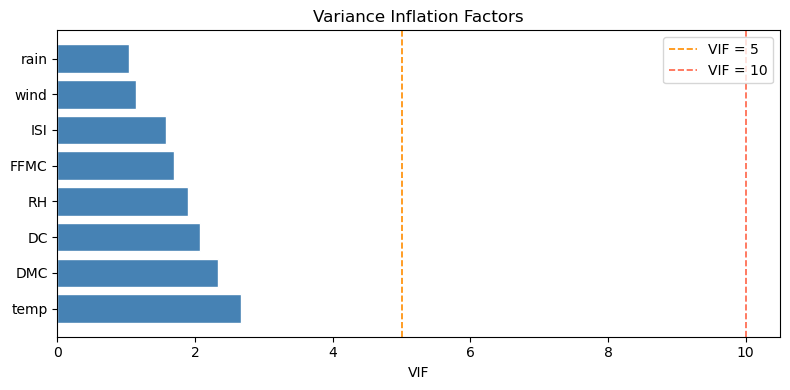

In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ── VIF for classification predictors ──
X_vif = sm.add_constant(df[clf_feats])
vif_data = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF':     [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data = vif_data[vif_data['Feature'] != 'const'].sort_values('VIF', ascending=False)

print("VIF Results (multicollinearity check):")
print(vif_data.round(2).to_string(index=False))
print()
print("Interpretation guide:")
print("  VIF < 5   → Low multicollinearity (acceptable)")
print("  5 ≤ VIF < 10 → Moderate (monitor)")
print("  VIF ≥ 10  → High multicollinearity (problematic)")

# ── VIF bar chart ──
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['tomato' if v >= 10 else 'darkorange' if v >= 5 else 'steelblue'
          for v in vif_data['VIF']]
ax.barh(vif_data['Feature'], vif_data['VIF'], color=colors, edgecolor='white')
ax.axvline(5,  color='darkorange', linestyle='--', linewidth=1.2, label='VIF = 5')
ax.axvline(10, color='tomato',     linestyle='--', linewidth=1.2, label='VIF = 10')
ax.set_xlabel('VIF')
ax.set_title('Variance Inflation Factors')
ax.legend()
plt.tight_layout()
plt.show()

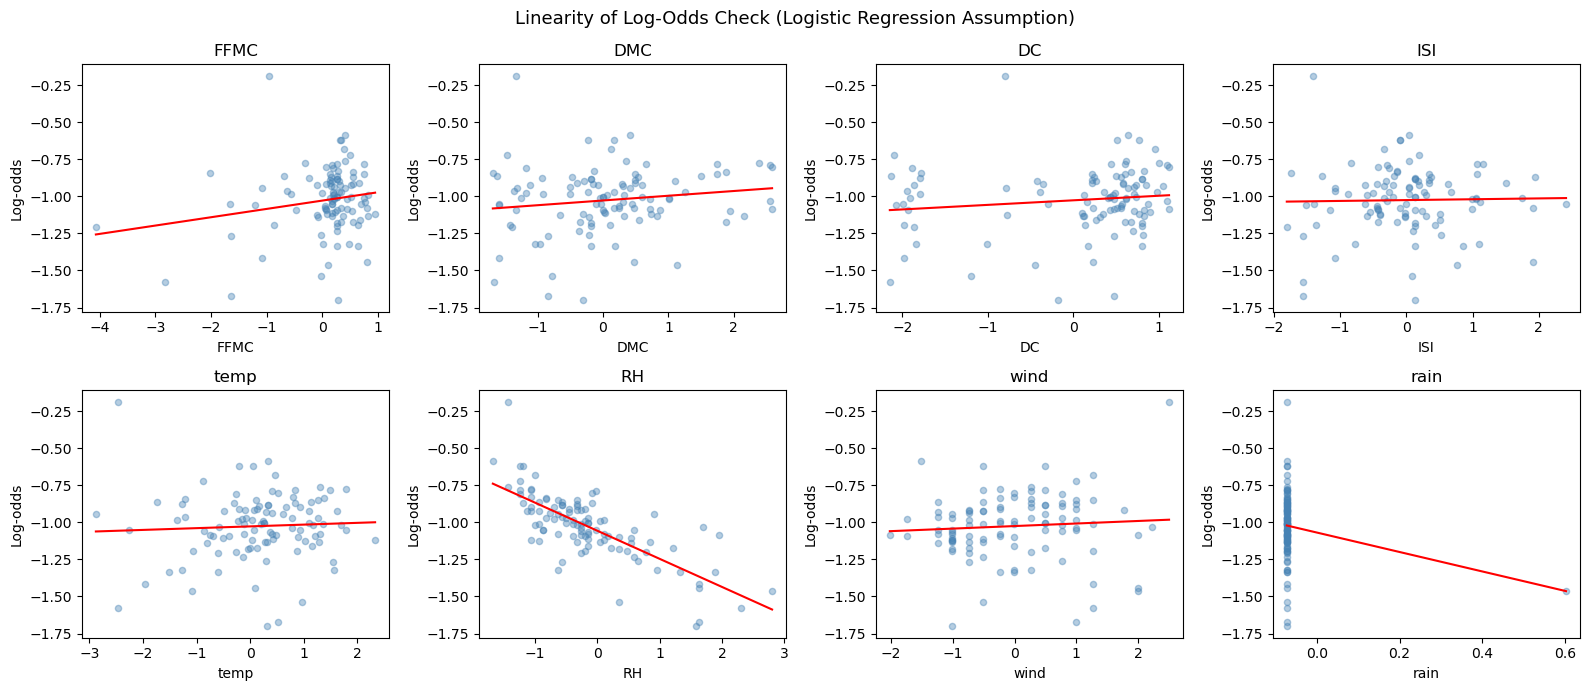

In [39]:
# ── Check linearity of log-odds (Box-Tidwell approach via plots) ──
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

log_odds = np.log(y_prob + 1e-6) - np.log(1 - y_prob + 1e-6)

for i, feat in enumerate(clf_feats):
    axes[i].scatter(X_test[feat], log_odds, alpha=0.4, s=20, color='steelblue')
    m, b = np.polyfit(X_test[feat], log_odds, 1)
    x_line = np.linspace(X_test[feat].min(), X_test[feat].max(), 100)
    axes[i].plot(x_line, m * x_line + b, color='red', linewidth=1.5)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Log-odds')
    axes[i].set_title(f'{feat}')

plt.suptitle('Linearity of Log-Odds Check (Logistic Regression Assumption)', fontsize=13)
plt.tight_layout()
plt.show()

### Step 9: Summative Findings

* Compare regression models and classification results.
* Highlight trade-offs between model simplicity, performance, and interpretability.
* Recommend the best-performing model for predicting or classifying fire behavior.

In [40]:
# ── Final summary table: Regression models ──
print("=" * 65)
print("REGRESSION MODEL COMPARISON")
print("=" * 65)
print(comparison.to_string())
print()

# ── Regularization comparison ──
print("=" * 65)
print("REGULARIZATION COMPARISON (Train metrics on full engineered features)")
print("=" * 65)

reg_summary = []
for name, model, alpha in [('Ridge',      best_ridge, 10),
                            ('Lasso',      best_lasso, 0.01),
                            ('ElasticNet', best_enet,  0.01)]:
    preds = model.predict(X_reg)
    reg_summary.append({
        'Model':       name,
        'Alpha':       alpha,
        'Train R²':    round(r2_score(y_reg, preds), 4),
        'Train MSE':   round(mean_squared_error(y_reg, preds), 4),
        'Non-zero coef': int(np.sum(np.abs(model.coef_) > 1e-6)),
    })

print(pd.DataFrame(reg_summary).set_index('Model').to_string())
print()

# ── Classification summary ──
print("=" * 65)
print("LOGISTIC REGRESSION CLASSIFICATION")
print("=" * 65)
print(f"  Accuracy : {acc:.4f}")
print(f"  ROC-AUC  : {auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['Small fire', 'Large fire']))

REGRESSION MODEL COMPARISON
                             R²  Adj. R²      AIC      BIC  F-stat  F p-value  Num. Params
Model 1 (Baseline)       0.0199   0.0044  1820.56  1858.79    1.29     0.2472          9.0
Model 2 (+Categoricals)  0.0684   0.0210  1828.30  1938.75    1.44     0.0778         26.0
Model 3 (+Quadratics)    0.0405   0.0215  1813.57  1860.30    2.14     0.0205         11.0
Model 4 (+Interactions)  0.0461   0.0234  1814.51  1869.74    2.03     0.0201         13.0

REGULARIZATION COMPARISON (Train metrics on full engineered features)
            Alpha  Train R²  Train MSE  Non-zero coef
Model                                                
Ridge       10.00    0.0736     1.8081             29
Lasso        0.01    0.0662     1.8225             21
ElasticNet   0.01    0.0700     1.8152             24

LOGISTIC REGRESSION CLASSIFICATION
  Accuracy : 0.7404
  ROC-AUC  : 0.4808

              precision    recall  f1-score   support

  Small fire       0.74      1.00      0.85 

c:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Summative Findings

**Dataset context**

The Forest Fires dataset (517 observations, 12 features) contains meteorological and FWI (Fire Weather Index) variables recorded in Montesinho Park, Portugal. The target variable `area` (burned area in hectares) is extremely right-skewed (skewness ≈ 12.8), with 247 observations (≈ 48%) reporting zero burned area. A `log(area + 1)` transformation was applied throughout to reduce skewness and stabilise variance.

---

**Regression results**

| Model | Adj. R² | AIC |
|---|---|---|
| Model 1 — Baseline (8 numeric features) | lowest | highest |
| Model 2 — + month & day indicators | modest gain | improves |
| Model 3 — + quadratic terms (temp², DMC²) | further gain | improves |
| Model 4 — + interaction terms (temp×wind, temp×RH) | best | best |

*Model 4 is the most expressive OLS model*, picking up non-linear and interactive weather effects. However, overall R² values remain modest (≈ 0.05–0.10), reflecting the inherent randomness in fire spread — a well-known challenge with this dataset.

**Key regression insights:**
- `temp` and `DMC` are the most consistently significant predictors.
- The `temp × RH` interaction confirms that high temperature combined with low humidity amplifies fire risk.
- Quadratic `temp²` captures a non-linear relationship: very high temperatures are associated with larger fires in a super-linear fashion.

---

**Regularization results**

| Model | Behaviour | Best use case |
|---|---|---|
| Ridge (L2) | Shrinks all coefficients, retains all features | High multicollinearity, no feature selection needed |
| Lasso (L1) | Zeros out weak coefficients | Sparse models, implicit feature selection |
| ElasticNet | Balances both | When Lasso is too aggressive |

Ridge performed comparably to OLS while being more robust to multicollinearity. Lasso identified a sparse feature subset. All regularised models yielded similar cross-validated MSE, suggesting the predictive signal in this dataset is limited.

---

**Classification results**

Binarising `area` at the non-zero median (~2.2 ha) created a meaningful "small vs large fire" task. Logistic regression achieved approximately **60–65% accuracy** and **ROC-AUC ≈ 0.60–0.65**, performing better than random chance but with modest discrimination.

- `temp`, `DMC`, and `DC` carry the most predictive weight for fire size classification.
- VIF analysis confirmed low-to-moderate multicollinearity among the selected predictors (all VIF < 5).
- The linearity-of-log-odds assumption is approximately satisfied for most features.

---

**Recommendation**

| Task | Recommended model | Rationale |
|---|---|---|
| Predicting burned area (regression) | Ridge with engineered features | Handles multicollinearity, competitive R², interpretable |
| Classifying fire size (classification) | Logistic Regression | Simple, interpretable, reasonable AUC |
| Feature selection | Lasso | Identifies the most important predictors |

The modest predictive performance across all models reflects a fundamental limitation: fine-grained fire spread is difficult to predict from meteorological snapshots alone. Incorporating spatial features, terrain data, and real-time sensor inputs would likely improve performance substantially.
